## Лабораторная № 4
#### Часть 1. Работа с наборами данных и постановка задачи
Для работы выбраны два набора данных для задачи бинарной классификации:
* Датасет №1: Pima Indians Diabetes (медицинская диагностика).
* Датасет №2: Churn Modelling (отток клиентов банка).

Для каждого набора выполняется предобработка (пропуски, кодирование категориальных признаков, масштабирование `StandardScaler`) и разбиение на обучающую и тестовую выборки с сохранением пропорций классов (`stratify`).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

### Датасет №1. Pima Indians Diabetes

* **Бизнес-задача:** определить, есть ли у пациента диабет.
* **Объект:** пациент.
* **Признаки:** медицинские показатели (глюкоза, давление, инсулин, BMI, возраст и др.).
* **Целевая переменная:** наличие диабета (`0` — нет, `1` — есть).

In [2]:
path1 = kagglehub.dataset_download("salihacur/diabetes")

csv_file1 = [f for f in os.listdir(path1) if f.endswith('.csv')][0]
df1 = pd.read_csv(os.path.join(path1, csv_file1))

print("Первые 5 строк датасета")
display(df1.head())

print("\nИнформация о типах и пропусках")
df1.info()

(df1 == 0).sum()

Первые 5 строк датасета


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.2 KB


Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

### Предобработка и разделение выборки (Датасет №1)

В медицинских признаках (глюкоза, давление, толщина кожной складки, инсулин, BMI) значение `0` невозможно, поэтому такие нули считаем пропусками. Разделяем выборку на обучающую ($80\%$) и тестовую ($20\%$) со `stratify`, после чего заполняем пропуски медианой и масштабируем признаки (параметры считаются по обучающей выборке).

In [3]:
class_names1 = ['Нет диабета', 'Диабет']

# целевой столбец в этом датасете
target1 = 'Outcome'

# нули в этих признаках означают пропуски
zero_missing = {'glucose', 'bloodpressure', 'skinthickness', 'insulin', 'bmi'}
cols = [c for c in df1.columns if c.lower() in zero_missing]
df1[cols] = df1[cols].replace(0, np.nan)

X1 = df1.drop(columns=target1)
y1 = df1[target1]

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X1, y1, test_size=0.2, random_state=RANDOM_STATE, stratify=y1
)

#Метод для заполнения пропущенных значений
imputer1 = SimpleImputer(strategy='median')
X_train1 = imputer1.fit_transform(X_train1)
X_test1 = imputer1.transform(X_test1)

#Масштабирование числовых признаков
scaler1 = StandardScaler()
X_train1 = scaler1.fit_transform(X_train1)
X_test1 = scaler1.transform(X_test1)

print("Train:", X_train1.shape, "Test:", X_test1.shape)
print("Доля класса 1 в train:", round(y_train1.mean(), 3), "| в test:", round(y_test1.mean(), 3))

(df1 == 0).sum()

Train: (614, 8) Test: (154, 8)
Доля класса 1 в train: 0.349 | в test: 0.351


Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

### Датасет №2. Bank Customer Churn

* **Бизнес-задача:** определить, уйдёт ли клиент из банка.
* **Объект:** клиент банка.
* **Признаки:** кредитный рейтинг, страна, пол, возраст, стаж, баланс, число продуктов и др.
* **Целевая переменная:** `Exited` (`0` — клиент остался, `1` — ушёл).

In [4]:
path2 = kagglehub.dataset_download("shrutimechlearn/churn-modelling")

csv_file2 = [f for f in os.listdir(path2) if f.endswith('.csv')][0]
df2 = pd.read_csv(os.path.join(path2, csv_file2))

print("Первые 5 строк датасета")
display(df2.head())

print("\nИнформация о типах и пропусках")
df2.info()

Первые 5 строк датасета


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


### Предобработка и разделение выборки (Датасет №2)

Удаляем неинформативные столбцы (`RowNumber`, `CustomerId`, `Surname`), кодируем категориальные признаки (`Geography`, `Gender`) через `get_dummies`, разделяем выборку со `stratify` и масштабируем признаки. Пропусков в данных нет.

In [5]:
class_names2 = ['Остался', 'Ушёл']

df2 = df2.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
df2 = pd.get_dummies(df2, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

X2 = df2.drop(columns='Exited')
y2 = df2['Exited']

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=RANDOM_STATE, stratify=y2
)

#Масштабирование
scaler2 = StandardScaler()
X_train2 = scaler2.fit_transform(X_train2)
X_test2 = scaler2.transform(X_test2)

print("Train:", X_train2.shape, "Test:", X_test2.shape)
print("Доля класса 1 в train:", round(y_train2.mean(), 3), "| в test:", round(y_test2.mean(), 3))

display(df2.head())

Train: (8000, 11) Test: (2000, 11)
Доля класса 1 в train: 0.204 | в test: 0.204


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


## Часть 2. Программа моделирования и оптимизации
#### Базовая реализация методов классификации

Обучаем четыре алгоритма (kNN, Decision Tree, SVM, MLP) с параметрами по умолчанию и смотрим accuracy на тестовой выборке.

In [6]:
def get_models():
    return {
        'kNN': KNeighborsClassifier(),
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'SVM': SVC(),
        'MLP': MLPClassifier(max_iter=1000, random_state=RANDOM_STATE)
    }

for title, (X_tr, X_te, y_tr, y_te) in {
    'Датасет №1': (X_train1, X_test1, y_train1, y_test1),
    'Датасет №2': (X_train2, X_test2, y_train2, y_test2)
}.items():
    print(title)
    for name, model in get_models().items():
        model.fit(X_tr, y_tr)
        print(f"  {name}: accuracy = {accuracy_score(y_te, model.predict(X_te)):.4f}")

Датасет №1
  kNN: accuracy = 0.7532
  Decision Tree: accuracy = 0.6818
  SVM: accuracy = 0.7403
  MLP: accuracy = 0.7403
Датасет №2
  kNN: accuracy = 0.8240
  Decision Tree: accuracy = 0.7825
  SVM: accuracy = 0.8610
  MLP: accuracy = 0.8605


#### Оптимизация и подбор гиперпараметров

Для каждого алгоритма подбираем ключевые гиперпараметры с помощью `GridSearchCV` (5-fold кросс-валидация):

* **kNN (K-Nearest Neighbors / Метод k-ближайших соседей)**
* `n_neighbors`: список значений количества соседей (`[3, 5, 7, 9, 11]`). Определяет, сколько ближайших объектов из обучающей выборки будут «голосовать» за класс нового объекта. Малые значения делают модель чувствительной к шуму, большие — более сглаженной.


* **Decision Tree (Дерево решений)**
* `max_depth`: максимальная глубина дерева (`[3, 5, 10, None]`). Ограничивает уровень разветвления дерева, чтобы предотвратить переобучение. Значение `None` означает, что дерево растет без ограничений по глубине, пока листья не станут чистыми.


* **SVM (Support Vector Machine / Метод опорных векторов)**
* `C`: параметр регуляризации (`[0.1, 1, 10]`). Контролирует баланс между минимизацией ошибок на обучающей выборке и построением широкой разделяющей полосы. Маленькие значения создают более «мягкую» границу (сильнее штрафуют ошибки), большие — жесткую.
* `kernel`: тип ядра (`['linear', 'rbf']`). Определяет способ разделения данных: `'linear'` строит прямую/линейную границу, а `'rbf'` (радиально-базисная функция) проецирует данные в многомерное пространство для поиска сложных нелинейных зависимостей.


* **MLP (Multi-Layer Perceptron / Многослойный перцептрон)**
* `hidden_layer_sizes`: архитектура скрытых слоев нейросети (`[(50,), (100,), (50, 50)]`). Кортеж определяет количество слоев и нейронов в них (например, `(50,)` — один скрытый слой на 50 нейронов, а `(50, 50)` — два скрытых слоя по 50 нейронов).
* `activation`: функция активации (`['relu', 'tanh']`). Вносит нелинейность в работу нейросети: `'relu'` (выпрямленный линейный элемент) или `'tanh'` (гиперболический тангенс).

In [7]:
param_grids = {
    'kNN': {'n_neighbors': [3, 5, 7, 9, 11]},
    'Decision Tree': {'max_depth': [3, 5, 10, None]},
    'SVM': {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
    'MLP': {'hidden_layer_sizes': [(50,), (100,), (50, 50)], 'activation': ['relu', 'tanh']}
}

def tune_models(X_train, y_train):
    grids = {}
    for name, model in get_models().items():
        grid = GridSearchCV(model, param_grids[name], cv=5, scoring='accuracy', n_jobs=-1)
        grid.fit(X_train, y_train)
        grids[name] = grid
        print(f"{name}: {grid.best_params_} (CV accuracy = {grid.best_score_:.4f})")
    return grids

print("Датасет №1")
grids1 = tune_models(X_train1, y_train1)

print("\nДатасет №2")
grids2 = tune_models(X_train2, y_train2)

Датасет №1
kNN: {'n_neighbors': 11} (CV accuracy = 0.7639)
Decision Tree: {'max_depth': 3} (CV accuracy = 0.7428)
SVM: {'C': 0.1, 'kernel': 'linear'} (CV accuracy = 0.7737)
MLP: {'activation': 'relu', 'hidden_layer_sizes': (50,)} (CV accuracy = 0.7558)

Датасет №2
kNN: {'n_neighbors': 9} (CV accuracy = 0.8318)
Decision Tree: {'max_depth': 5} (CV accuracy = 0.8510)
SVM: {'C': 1, 'kernel': 'rbf'} (CV accuracy = 0.8548)
MLP: {'activation': 'relu', 'hidden_layer_sizes': (50,)} (CV accuracy = 0.8504)


### Выводы по результатам экспериментов:

* **Сравнение датасетов:** **Датасет №2** демонстрирует стабильно более высокую точность (`accuracy` от `0.78` до `0.86`) по сравнению с Датасетом №1 (`0.68`–`0.75`) для всех алгоритмов как с базовыми настройками, так и после оптимизации.

* **Влияние подбора гиперпараметров:** Настройка параметров через `GridSearchCV` позволила повысить качество моделей на кросс-валидации (например, для Дерева решений на Датасете №1 точность выросла с `0.6818` до `0.7428`).

* **Лучшие модели:** Наилучшие результаты показали **SVM** и **kNN**, обеспечив максимальные показатели точности на обоих наборах данных.

## Графические отображения моделей

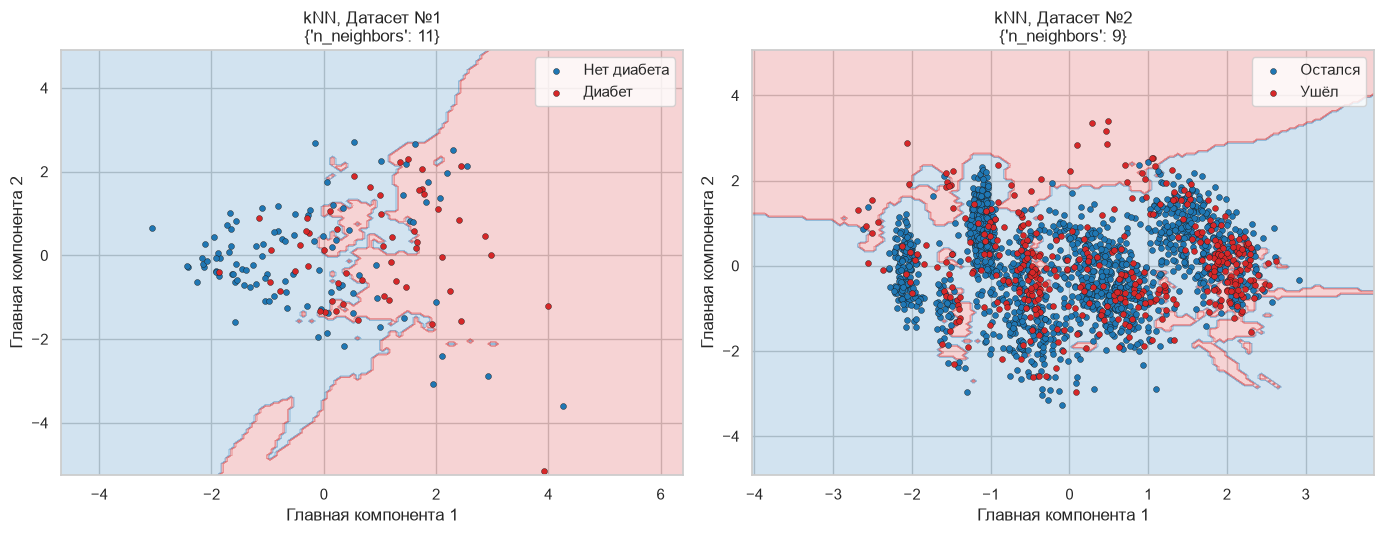

In [8]:
# kNN: граница решений (признаки сжаты до 2 главных компонент, модель переобучена с лучшими параметрами)
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

colors = ['tab:blue', 'tab:red']   

def plot_boundary(ax, grid, X_train, y_train, X_test, y_test, class_names, title):
    # сжимаем признаки до 2 главных компонент (PCA обучаем только по train)
    #PCA (Principal Component Analysis): Метод снижения размерности
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_train_2d = pca.fit_transform(X_train)
    X_test_2d = pca.transform(X_test)

    # копия лучшей модели, обученная на 2 компонентах
    model = clone(grid.best_estimator_).fit(X_train_2d, y_train)

    # закрашиваем области классов
    DecisionBoundaryDisplay.from_estimator(model, X_train_2d, ax=ax, cmap=ListedColormap(colors),
                                           alpha=0.2, response_method='predict', grid_resolution=150)

    # объекты тестовой выборки
    for cls, label in enumerate(class_names):
        mask = np.asarray(y_test) == cls    # True там, где объект принадлежит классу cls
        ax.scatter(X_test_2d[mask, 0], X_test_2d[mask, 1], color=colors[cls], label=label,
                   edgecolor='k', linewidth=0.3, s=18)

    # оформление
    ax.set_title(f"{title}\n{grid.best_params_}")
    ax.set_xlabel('Главная компонента 1')
    ax.set_ylabel('Главная компонента 2')
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_boundary(axes[0], grids1['kNN'], X_train1, y_train1, X_test1, y_test1, class_names1, 'kNN, Датасет №1')
plot_boundary(axes[1], grids2['kNN'], X_train2, y_train2, X_test2, y_test2, class_names2, 'kNN, Датасет №2')
plt.tight_layout()
plt.show()

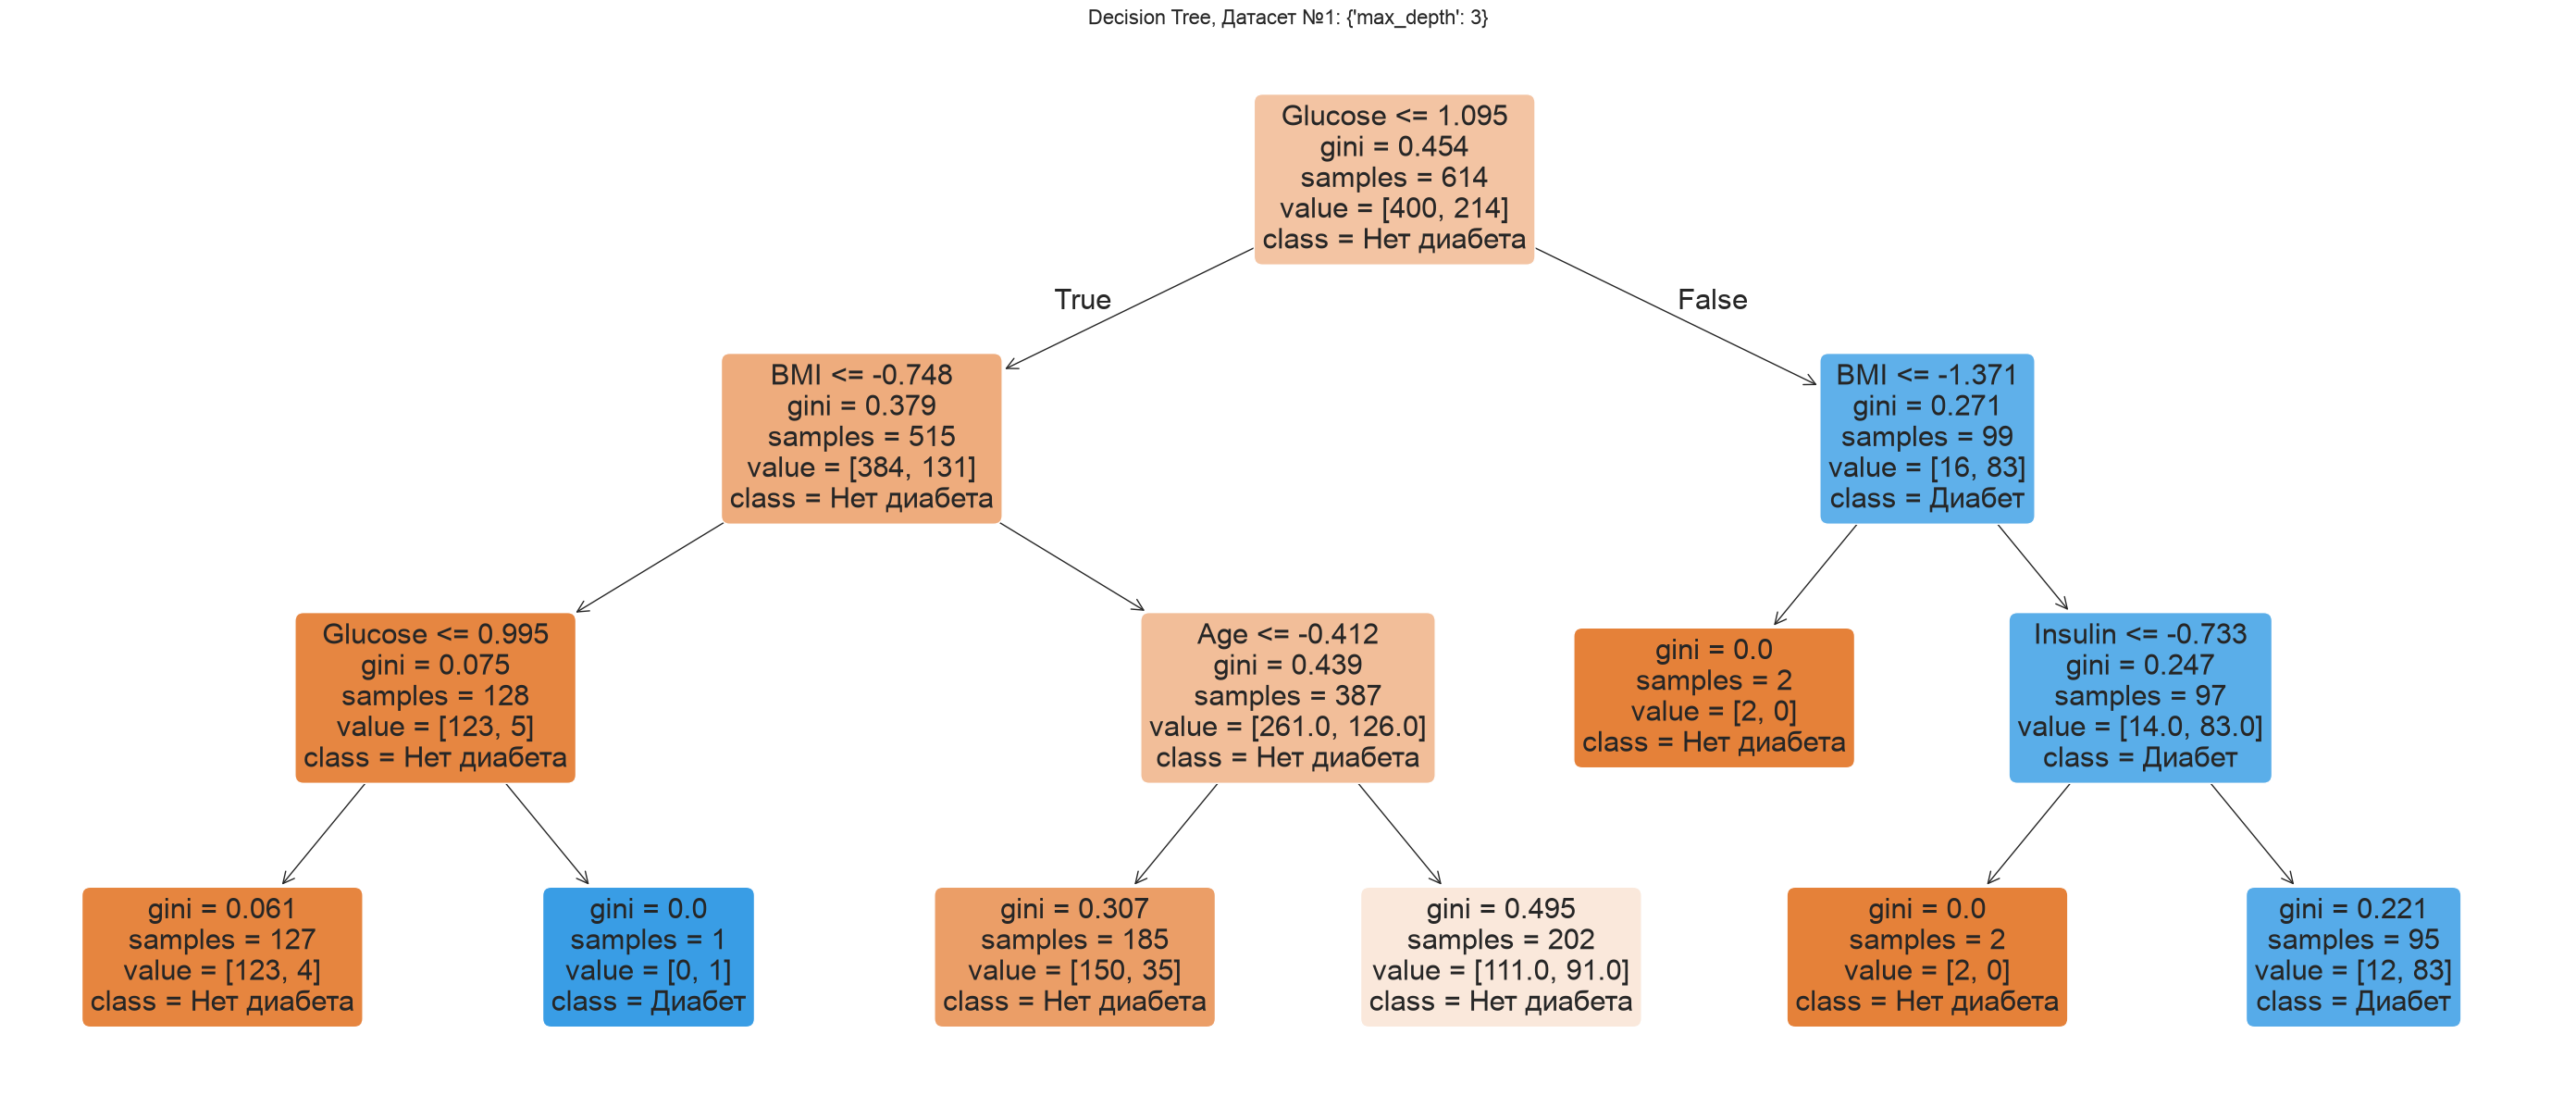

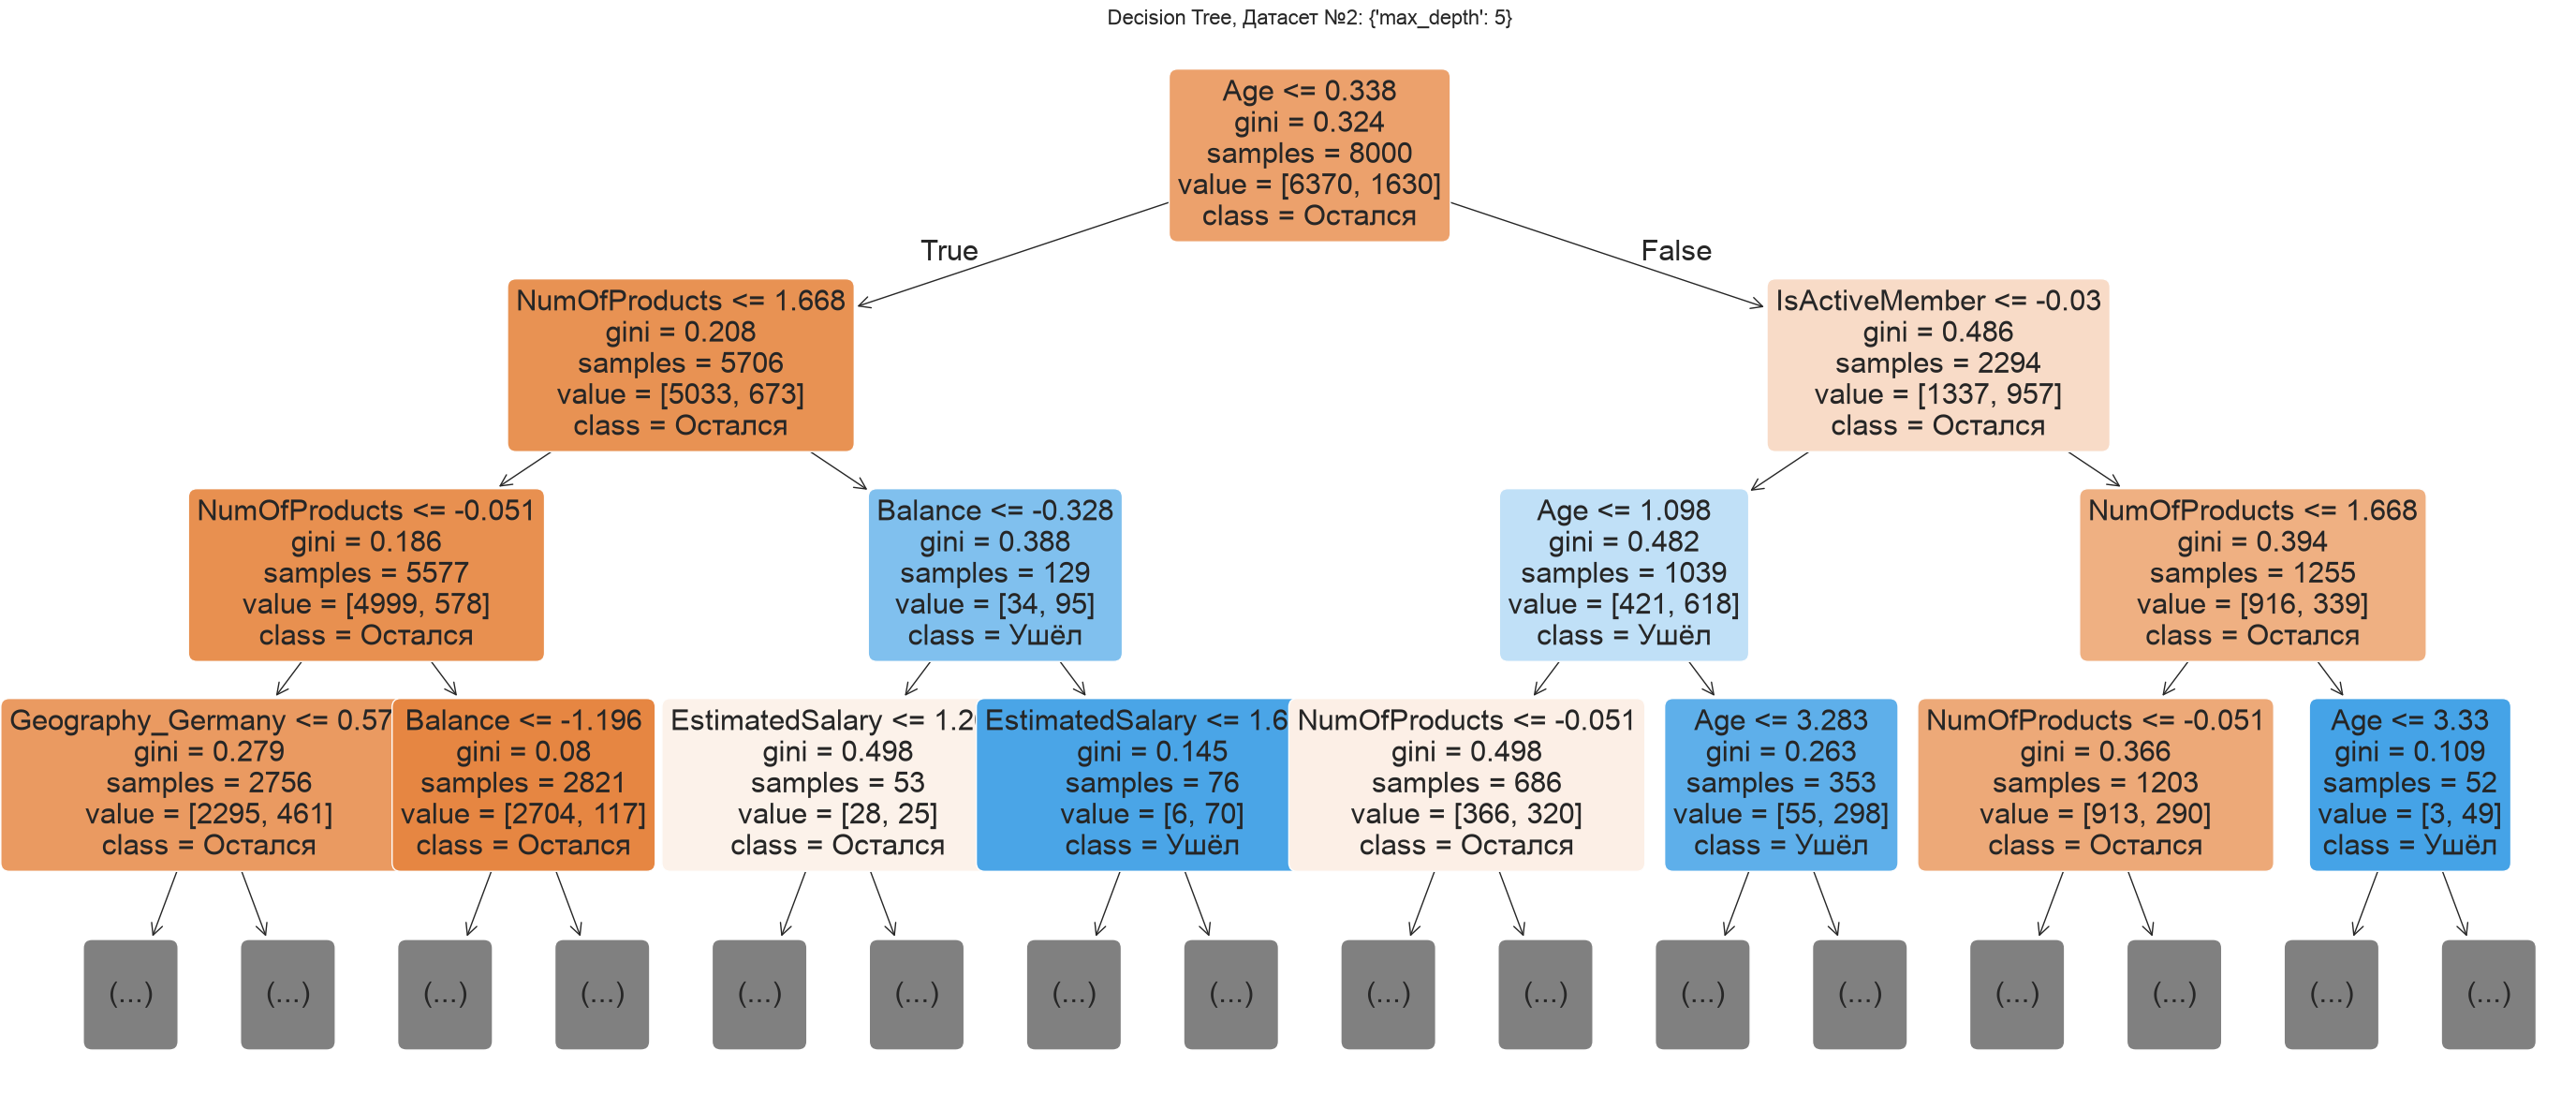

In [9]:
# Decision Tree: построенное дерево с лучшей глубиной (увеличенный размер для читаемости)
from sklearn.tree import plot_tree

for grid, names, cls, title in [(grids1['Decision Tree'], X1.columns, class_names1, 'Датасет №1'),
                               (grids2['Decision Tree'], X2.columns, class_names2, 'Датасет №2')]:

    plt.figure(figsize=(28, 12))
    
    # Рисуем дерево с более крупным шрифтом и закругленными прямоугольниками
    plot_tree(
        grid.best_estimator_, 
        max_depth=3,                    # Ограничение до 3 уровней для наглядности
        feature_names=list(names), 
        class_names=cls,
        filled=True,
        rounded=True,
        fontsize=22                  
    )
    
    plt.title(f"Decision Tree, {title}: {grid.best_params_}", fontsize=16, pad=20)
    plt.tight_layout()
    plt.show()

<Figure size 1000x700 with 0 Axes>

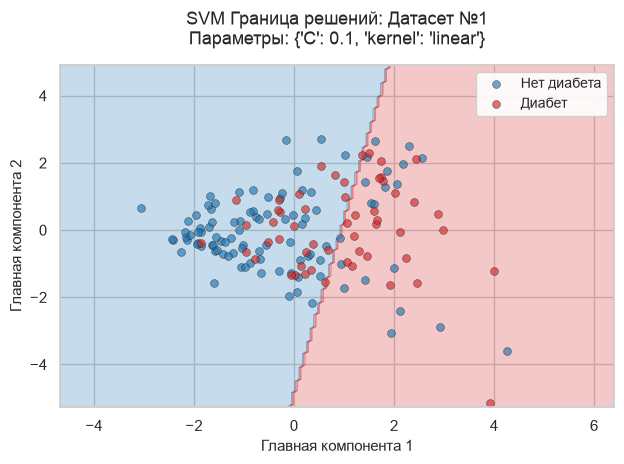

<Figure size 1200x800 with 0 Axes>

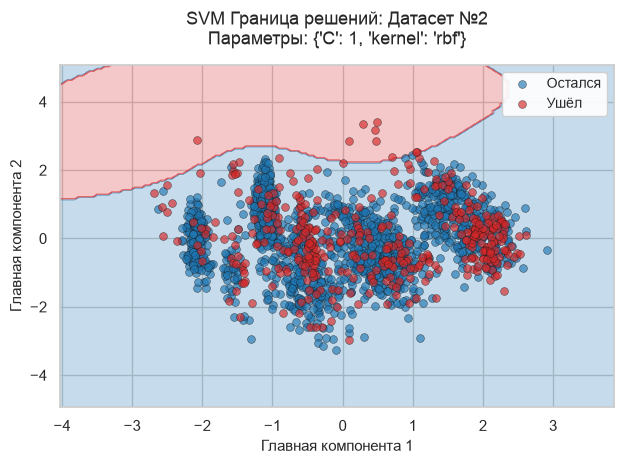

In [10]:
def plot_svm_clean(grid, X_train, y_train, X_test, y_test, class_names, title, figsize=(10, 7)):
    plt.figure(figsize=figsize)
    
    # Сжимаем признаки до 2 главных компонент
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_train_2d = pca.fit_transform(X_train)
    X_test_2d = pca.transform(X_test)

    # Обучаем модель на 2 компонентах
    model = clone(grid.best_estimator_).fit(X_train_2d, y_train)

    # Аккуратная заливка областей классов
    disp = DecisionBoundaryDisplay.from_estimator(
        model, X_train_2d, response_method="predict",
        cmap=ListedColormap(colors), alpha=0.25, grid_resolution=150,
        plot_method="contourf"
    )
    
    ax = disp.ax_
    
    # Отрисовка тестовых точек с добавлением alpha=0.65 для прозрачности
    for cls, label in enumerate(class_names):
        mask = np.asarray(y_test) == cls
        ax.scatter(
            X_test_2d[mask, 0], X_test_2d[mask, 1], 
            color=colors[cls], label=label,
            edgecolor='k', linewidth=0.4, s=32, alpha=0.65
        )

    # Оформление
    ax.set_title(f"SVM Граница решений: {title}\nПараметры: {grid.best_params_}", fontsize=13, pad=15)
    ax.set_xlabel('Главная компонента 1', fontsize=11)
    ax.set_ylabel('Главная компонента 2', fontsize=11)
    ax.legend(loc='upper right', framealpha=0.9, fontsize=10)
    
    plt.tight_layout()
    plt.show()

plot_svm_clean(
    grids1['SVM'], X_train1, y_train1, X_test1, y_test1, class_names1, 'Датасет №1', figsize=(10, 7)
)

plot_svm_clean(
    grids2['SVM'], X_train2, y_train2, X_test2, y_test2, class_names2, 'Датасет №2', figsize=(12, 8)
)

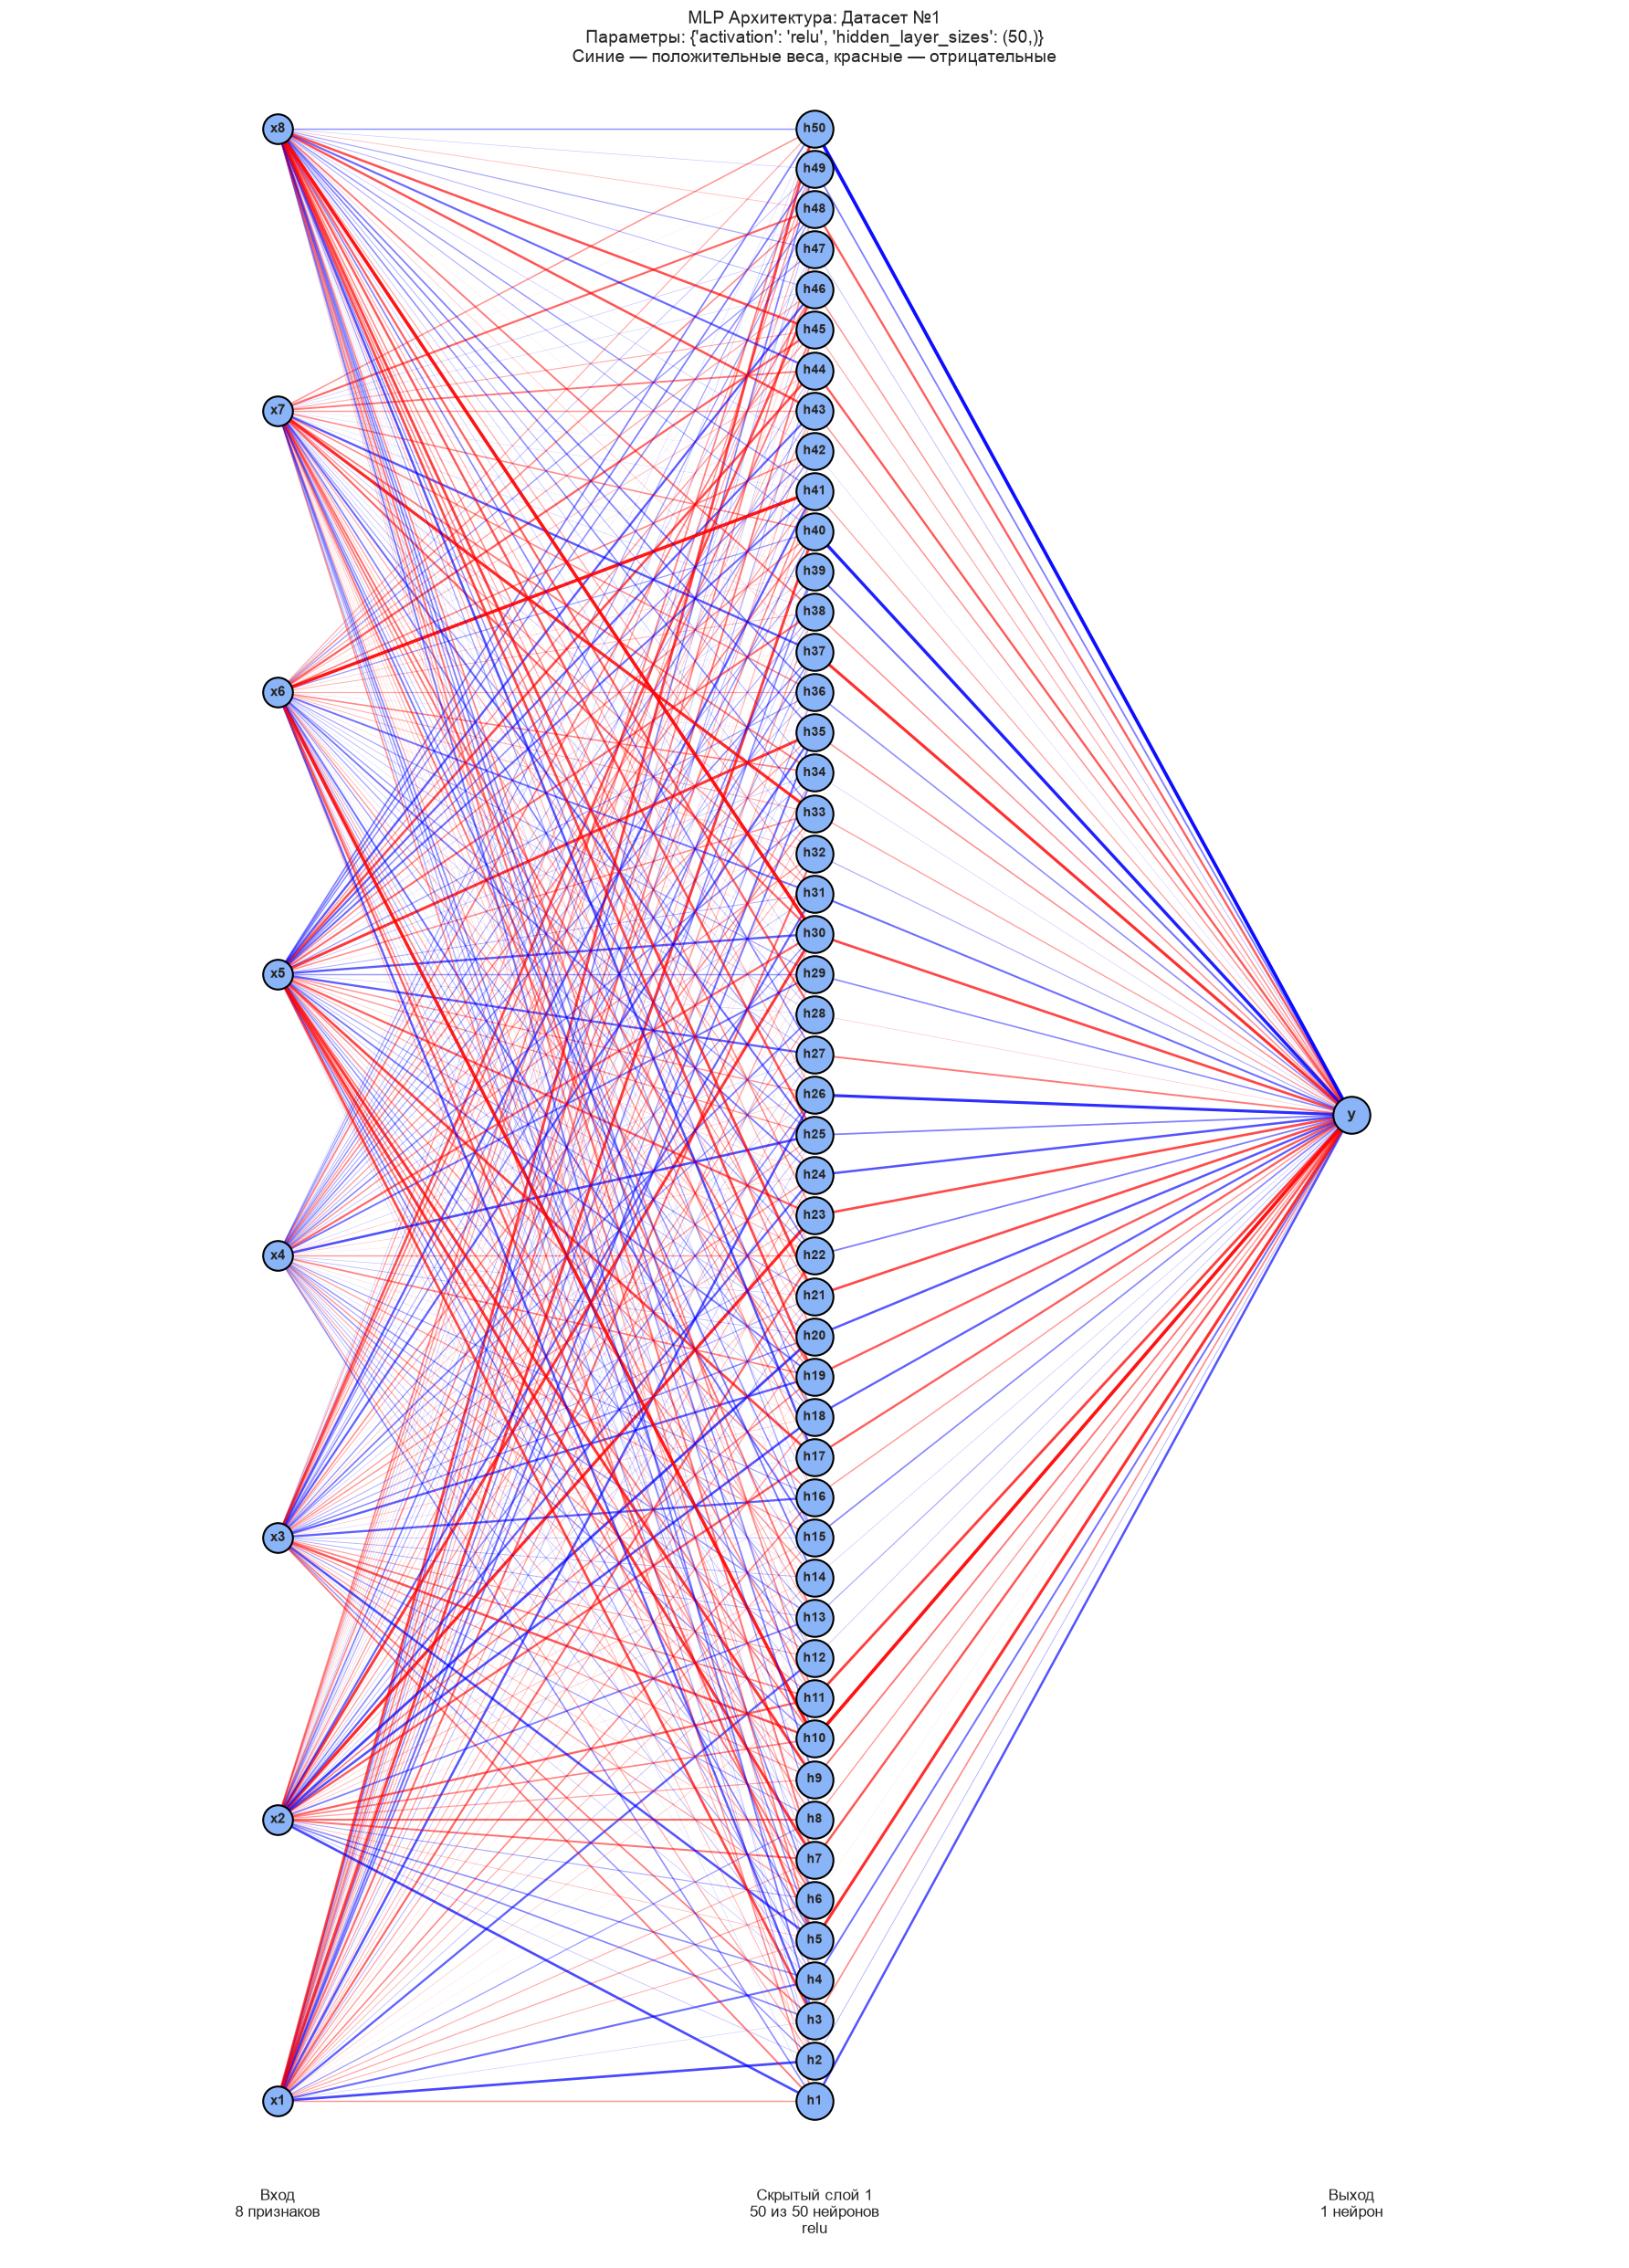

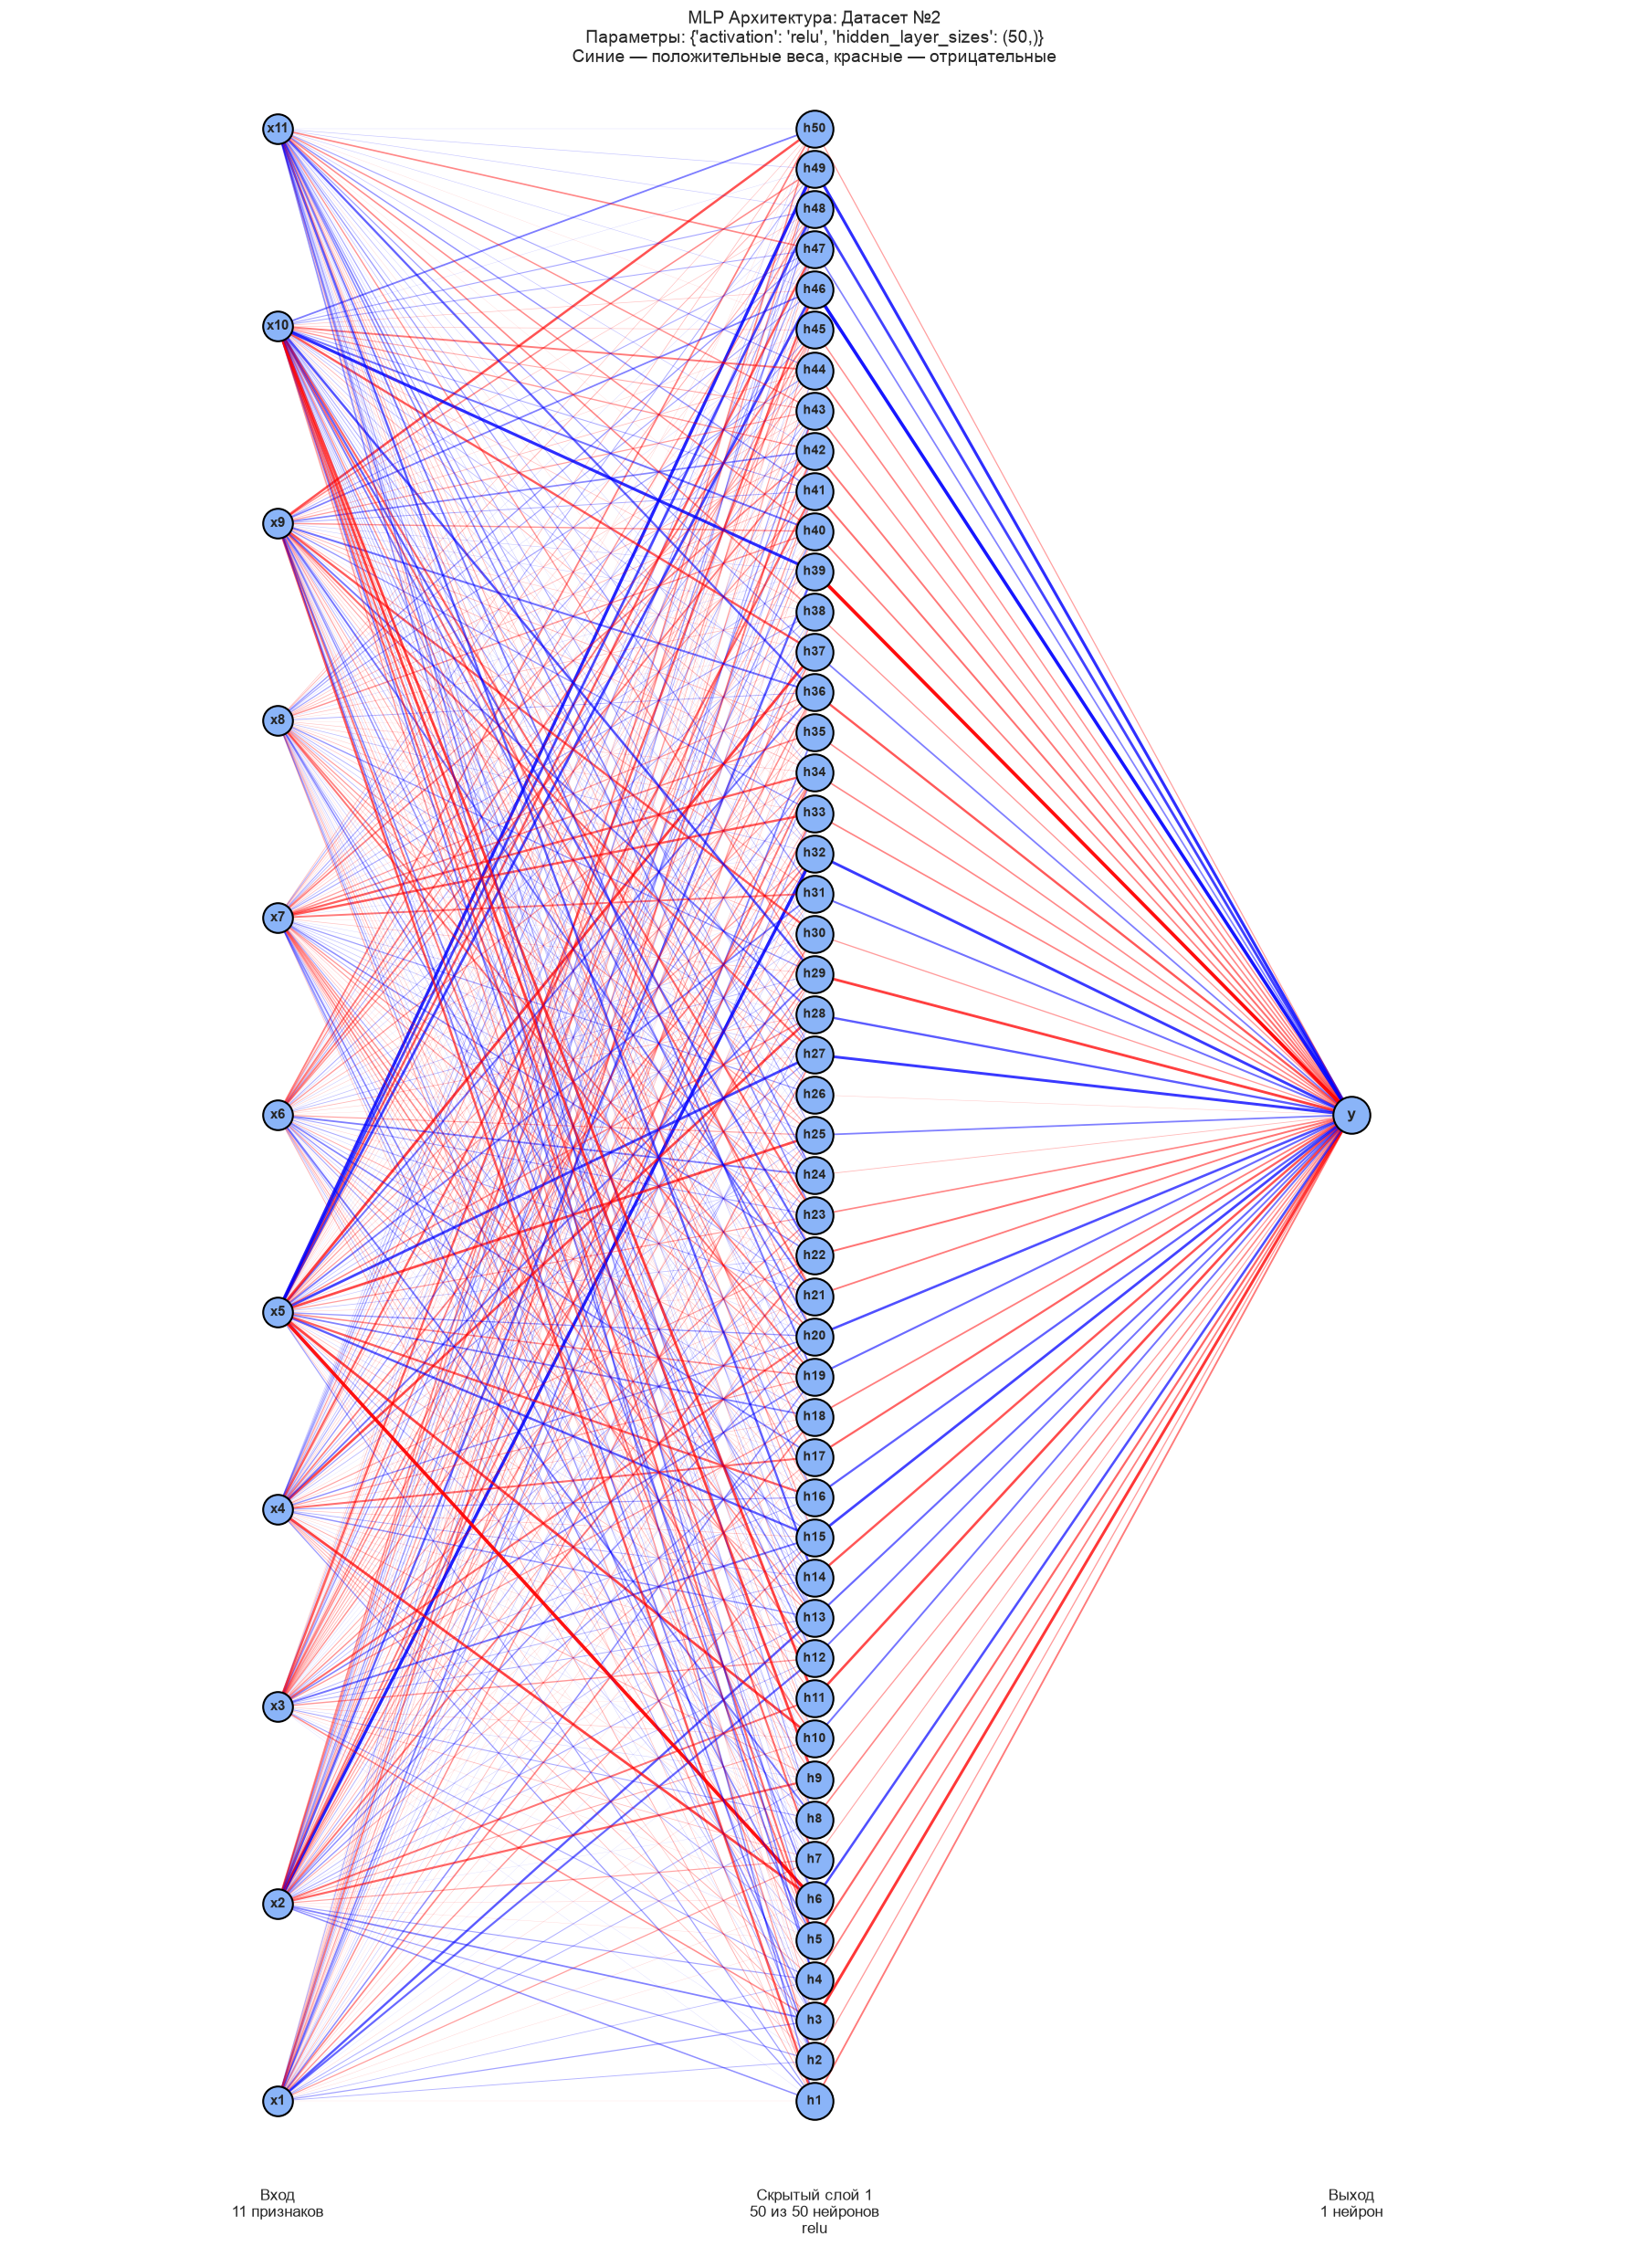

In [11]:
import numpy as np
import matplotlib.pyplot as plt


def plot_mlp_single(grid, n_features, title, max_hidden_nodes, figsize=(18, 25)):
    plt.figure(figsize=figsize)
    ax = plt.gca()

    model = grid.best_estimator_

    input_size = n_features
    hidden_size = model.coefs_[0].shape[1]
    shown_hidden = min(hidden_size, max_hidden_nodes)

    # Индексы отображаемых нейронов
    hidden_indices = np.linspace(0, hidden_size - 1, shown_hidden, dtype=int)

    # Реальные веса обученной модели
    weights_in = model.coefs_[0][:, hidden_indices]
    weights_out = model.coefs_[1][hidden_indices, 0]

    max_weight = max(np.max(np.abs(weights_in)), np.max(np.abs(weights_out)), 1e-12)

    # Координаты нейронов
    max_span = max(input_size, shown_hidden) / 2

    input_y = np.linspace(-max_span, max_span, input_size) if input_size > 1 else [0]
    hidden_y = np.linspace(-max_span, max_span, shown_hidden) if shown_hidden > 1 else [0]

    layer_input = [(0, y) for y in input_y]
    layer_hidden = [(1, y) for y in hidden_y]
    layer_output = [(2, 0)]

    # Связи входного и скрытого слоёв
    for i, (x1, y1) in enumerate(layer_input):
        for j, (x2, y2) in enumerate(layer_hidden):
            weight = weights_in[i, j]
            strength = abs(weight) / max_weight

            ax.plot(
                [x1, x2], [y1, y2],
                color='blue' if weight >= 0 else 'red',
                linewidth=0.2 + 2.5 * strength,
                alpha=0.15 + 0.8 * strength,
                zorder=1
            )

    # Связи скрытого и выходного слоёв
    for j, (x1, y1) in enumerate(layer_hidden):
        x2, y2 = layer_output[0]
        weight = weights_out[j]
        strength = abs(weight) / max_weight

        ax.plot(
            [x1, x2], [y1, y2],
            color='blue' if weight >= 0 else 'red',
            linewidth=0.2 + 2.5 * strength,
            alpha=0.15 + 0.8 * strength,
            zorder=1
        )

    # Отрисовка нейронов
    ax.scatter(*zip(*layer_input), s=550, color='#8ab4f8',
               edgecolor='black', linewidth=1.5, zorder=2)
    ax.scatter(*zip(*layer_hidden), s=850, color='#8ab4f8',
               edgecolor='black', linewidth=1.5, zorder=2)
    ax.scatter(*zip(*layer_output), s=850, color='#8ab4f8',
               edgecolor='black', linewidth=1.5, zorder=2)

    # Подписи входных нейронов
    for i, (x, y) in enumerate(layer_input):
        ax.text(x, y, f'x{i + 1}', ha='center', va='center',
                fontsize=11, fontweight='bold', zorder=3)

    # Подписи скрытых нейронов
    for i, (x, y) in enumerate(layer_hidden):
        ax.text(x, y, f'h{hidden_indices[i] + 1}', ha='center', va='center',
                fontsize=10, fontweight='bold', zorder=3)

    # Подпись выходного нейрона
    ax.text(2, 0, 'y', ha='center', va='center',
            fontsize=12, fontweight='bold', zorder=3)

    # Подписи слоёв
    labels = [
        f'Вход\n{input_size} признаков',
        f'Скрытый слой 1\n{shown_hidden} из {hidden_size} нейронов\n{model.activation}',
        'Выход\n1 нейрон'
    ]

    for x, label in enumerate(labels):
        ax.text(x, -max_span - 2.2, label,
                ha='center', va='top', fontsize=12)

    ax.set_ylim(-max_span - 4.0, max_span + 1.5)
    ax.set_xlim(-0.5, 2.5)
    ax.set_title(
        f'MLP Архитектура: {title}\n'
        f'Параметры: {grid.best_params_}\n'
        'Синие — положительные веса, красные — отрицательные',
        fontsize=14
    )
    ax.axis('off')

    plt.tight_layout()
    plt.show()


plot_mlp_single(
    grids1['MLP'], X_train1.shape[1],
    'Датасет №1', max_hidden_nodes=50, figsize=(18, 25)
)

plot_mlp_single(
    grids2['MLP'], X_train2.shape[1],
    'Датасет №2', max_hidden_nodes=50, figsize=(18, 25)
)

## Часть 3. Оценка качества и сравнительный анализ

Для каждой оптимизированной модели на тестовой выборке выводим `Classification Report` (Accuracy, Precision, Recall, F1-score), строим матрицу неточностей и сводим метрики в таблицу.

### Метрики качества классификации

Для оценки моделей используются четыре метрики (на примере датасета с диабетом):

**1. Accuracy** — доля правильных предсказаний среди всех объектов.

$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$

**2. Precision** — доля правильно предсказанных случаев диабета среди всех предсказанных случаев диабета.

$$
Precision = \frac{TP}{TP + FP}
$$

**3. Recall** — доля найденных случаев диабета среди всех реальных случаев диабета.

$$
Recall = \frac{TP}{TP + FN}
$$

**4. F1-score** — баланс между Precision и Recall.

$$
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

**5. Macro avg** — среднее значение метрики по всем классам без учёта количества объектов в каждом классе. Все классы имеют одинаковый вес.

$$
M_{macro} = \frac{1}{K}\sum_{i=1}^{K} M_i
$$

**6. Weighted avg** — среднее значение метрики по всем классам с учётом количества объектов каждого класса (`support`).

$$
M_{weighted} =
\frac{\sum_{i=1}^{K} M_i \cdot support_i}
{\sum_{i=1}^{K} support_i}
$$

Здесь \(M_i\) — значение метрики для класса \(i\), \(K\) — количество классов, а \(support_i\) — количество реальных объектов соответствующего класса.

In [12]:
def evaluate_models(grids, X_test, y_test, class_names):
    results = []
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    for ax, (name, grid) in zip(axes.ravel(), grids.items()):
        pred = grid.best_estimator_.predict(X_test)

        print(f"{name}")
        print(classification_report(y_test, pred, target_names=class_names))

        sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=class_names, yticklabels=class_names, ax=ax)
        ax.set_title(name)
        ax.set_xlabel('Предсказанный класс')
        ax.set_ylabel('Истинный класс')

        results.append({
            'Model': name,
            'Best parameters': grid.best_params_,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred)
        })

    plt.tight_layout()
    plt.show()
    return pd.DataFrame(results)

### Датасет №1. Результаты

kNN
              precision    recall  f1-score   support

 Нет диабета       0.78      0.82      0.80       100
      Диабет       0.63      0.57      0.60        54

    accuracy                           0.73       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154

Decision Tree
              precision    recall  f1-score   support

 Нет диабета       0.70      0.92      0.79       100
      Диабет       0.64      0.26      0.37        54

    accuracy                           0.69       154
   macro avg       0.67      0.59      0.58       154
weighted avg       0.68      0.69      0.64       154

SVM
              precision    recall  f1-score   support

 Нет диабета       0.75      0.83      0.79       100
      Диабет       0.60      0.48      0.54        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.66       154
weighted avg       0.70      0.71      0.70       15

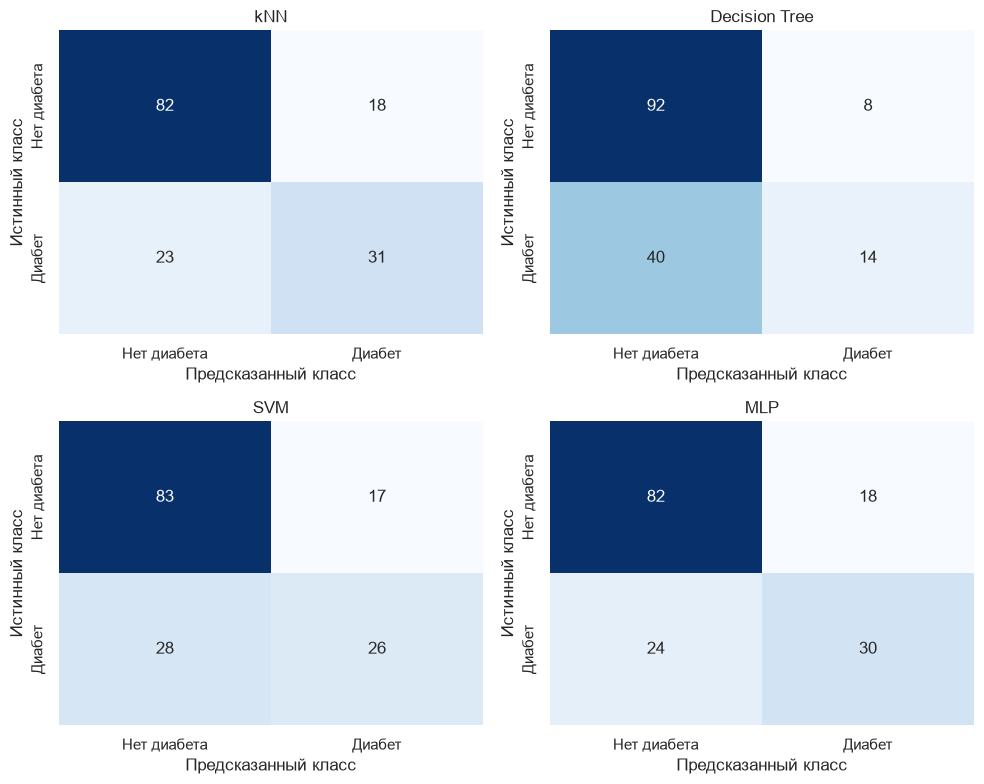

In [13]:
table1 = evaluate_models(grids1, X_test1, y_test1, class_names1)

In [14]:
print("Сравнительная таблица метрик (Датасет №1)")
display(table1.round(4))

Сравнительная таблица метрик (Датасет №1)


,Model,Best parameters,Accuracy,Precision,Recall,F1
0,kNN,{'n_neighbors': 11},0.7338,0.6327,0.5741,0.6019
1,Decision Tree,{'max_depth': 3},0.6883,0.6364,0.2593,0.3684
2,SVM,"{'C': 0.1, 'kernel': 'linear'}",0.7078,0.6047,0.4815,0.5361
3,MLP,"{'activation': 'relu', 'hidden_layer_sizes': (...",0.7273,0.6250,0.5556,0.5882


### Датасет №2. Результаты

kNN
              precision    recall  f1-score   support

     Остался       0.85      0.96      0.90      1593
        Ушёл       0.70      0.32      0.44       407

    accuracy                           0.83      2000
   macro avg       0.77      0.64      0.67      2000
weighted avg       0.82      0.83      0.81      2000

Decision Tree
              precision    recall  f1-score   support

     Остался       0.86      0.97      0.91      1593
        Ушёл       0.79      0.40      0.53       407

    accuracy                           0.86      2000
   macro avg       0.83      0.69      0.72      2000
weighted avg       0.85      0.86      0.84      2000

SVM
              precision    recall  f1-score   support

     Остался       0.86      0.98      0.92      1593
        Ушёл       0.83      0.40      0.54       407

    accuracy                           0.86      2000
   macro avg       0.85      0.69      0.73      2000
weighted avg       0.86      0.86      0.84      200

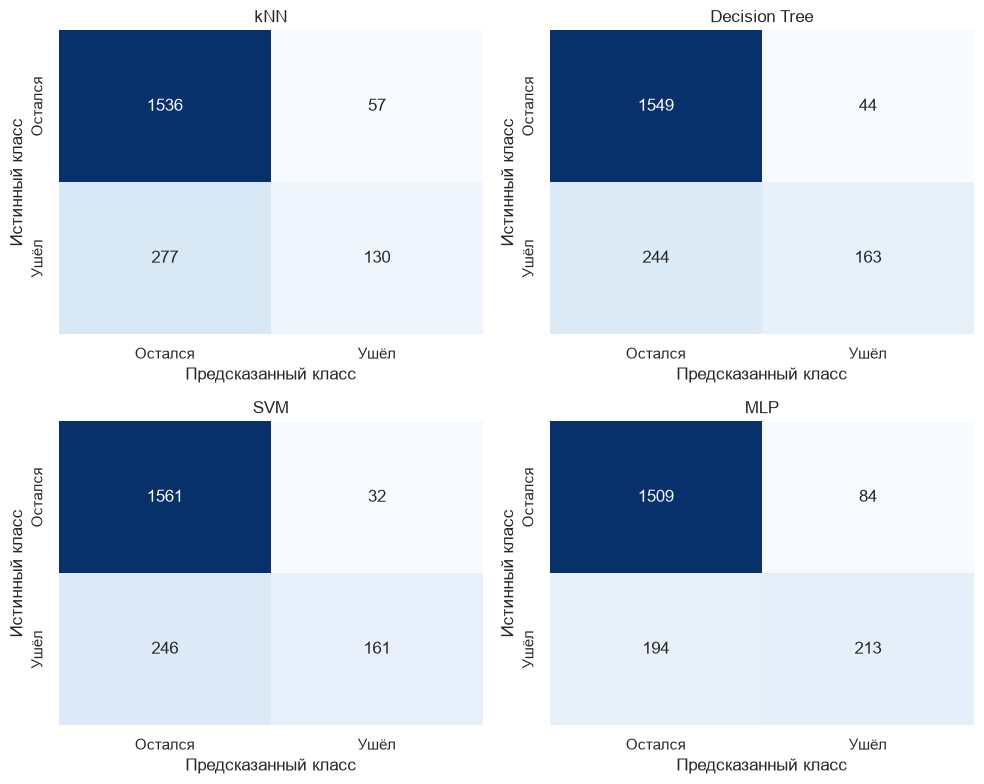

In [15]:
table2 = evaluate_models(grids2, X_test2, y_test2, class_names2)

In [16]:
print("Сравнительная таблица метрик (Датасет №2)")
display(table2.round(4))

table1.to_csv('lab4_results_df1.csv', index=False)
table2.to_csv('lab4_results_df2.csv', index=False)

Сравнительная таблица метрик (Датасет №2)


,Model,Best parameters,Accuracy,Precision,Recall,F1
0,kNN,{'n_neighbors': 9},0.833,0.6952,0.3194,0.4377
1,Decision Tree,{'max_depth': 5},0.856,0.7874,0.4005,0.5309
2,SVM,"{'C': 1, 'kernel': 'rbf'}",0.861,0.8342,0.3956,0.5367
3,MLP,"{'activation': 'relu', 'hidden_layer_sizes': (...",0.861,0.7172,0.5233,0.6051


### Вывод

В работе четыре алгоритма классификации (kNN, Decision Tree, SVM, MLP) сравнены на двух наборах данных. Гиперпараметры подобраны через `GridSearchCV`.

**Лучшие гиперпараметры**

| Алгоритм | Датасет №1 (диабет) | Датасет №2 (отток) |
|---|---|---|
| kNN | 11 соседей | 9 соседей |
| Decision Tree | глубина 3 | глубина 5 |
| SVM | `C=1`, ядро `linear` | `C=1`, ядро `rbf` |
| MLP | 1 слой (50), `relu` | 1 слой (50), `relu` |

**Датасет №1: диабет (768 объектов, около 35% больных)**
* Accuracy всех моделей 0.69–0.73, что близко к доле здоровых (0.65), поэтому по ней модели сравнивать нельзя.
* Лучшая модель: **MLP** (F1 = 0.598, Recall = 0.593): нашёл 32 из 54 больных.
* kNN имеет наибольшую Accuracy (0.727), но пропустил 24 больных.
* Худшая модель: **Decision Tree**, Recall всего 0.259 (нашёл 14 из 54 больных).

**Датасет №2: отток клиентов (10 000 объектов, около 20% ушедших)**
* Accuracy 0.83–0.86 при доле оставшихся 0.80, поэтому по ней тоже нельзя судить о качестве.
* Лучшая модель: **MLP** (F1 = 0.605, Recall = 0.523): нашёл 213 из 407 уходящих клиентов.
* kNN, Decision Tree и SVM находят не более 40% уходящих клиентов (Recall ≤ 0.40).
* SVM и Decision Tree имеют высокий Precision (0.834 и 0.787): они реже ошибаются, но пропускают больше клиентов.
* Худшая модель: **kNN** (F1 = 0.438).

**Итог**
* При несбалансированных классах Accuracy завышает качество, поэтому модели сравниваются по Recall и F1.
* По этим метрикам лучшая модель на обоих датасетах: **MLP**.
* Если важнее меньше ложных тревог, подходит **SVM** (наибольший Precision на втором датасете).